## Содержание:
* [Стационарность](#stacionary)
* [Преобразование Бокса-Кокса](#boxcox)
* [Модели для предсказания значений временного ряда](#predict)
* [Метрики точности прогноза](#metrics)

Импортируем библиотеки

In [1]:
# Импортируем необходимые библиотеки

import os
from os import path
from matplotlib import pyplot as plt
import pandas as pd
import numpy as np
import statsmodels.tsa.api as smt

Рутина с датасетами

In [2]:
# аналогичным образом загружаем данные о пассажирах
df = pd.read_csv('data/chai_stall_diaries.csv')
# неподходящий формат данных приводим к тому, с которым Pandas может работать
df['date'] = pd.to_datetime(df['date'])
# также устанавливаем индекс и сортируем
df.set_index('date').sort_index()

,day_of_week,month,is_weekend,temp_c,rain_mm,cricket_match_day,exam_season,special_day,staff_on_duty,chai_price_pkr,chai_cups_sold,coffee_cups_sold,samosas_sold,busiest_hour,customer_rating,daily_revenue_pkr
date,,,,,,,,,,,,,,,,
2024-10-01,Tuesday,October,0,25.3,0.0,No,No,NaN,1,65,55,14,25,6 PM,4.0,5885
2024-10-02,Wednesday,October,0,26.1,0.0,No,No,NaN,1,64,35,14,17,4 PM,4.5,4281
2024-10-03,Thursday,October,0,24.7,0.0,No,No,NaN,1,62,51,13,32,6 PM,4.5,5396
2024-10-04,Friday,October,1,21.9,0.0,No,No,NaN,3,64,71,23,36,6 PM,NaN,8041
2024-10-05,Saturday,October,1,NaN,0.0,No,No,NaN,3,60,78,25,48,6 PM,4.0,8631
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-26,Saturday,September,1,25.8,0.0,No,No,NaN,2,79,53,27,22,4 PM,4.0,8189
2026-09-27,Sunday,September,1,24.8,0.0,No,No,NaN,2,82,59,21,36,6 PM,4.5,8449
2026-09-28,Monday,September,0,29.8,0.0,No,No,NaN,1,82,36,24,28,4 PM,3.0,6776


In [3]:
df.describe()

,date,is_weekend,temp_c,rain_mm,staff_on_duty,chai_price_pkr,chai_cups_sold,coffee_cups_sold,samosas_sold,customer_rating,daily_revenue_pkr
count,733,733.000000,712.000000,733.000000,733.000000,733.000000,733.000000,733.000000,733.000000,690.000000,733.000000
mean,2025-09-29 23:16:46.821282,0.429741,21.007584,2.097271,1.986357,71.572988,79.766712,23.156889,48.990450,4.084783,9653.121419
min,2024-10-01 00:00:00,0.000000,3.600000,0.000000,1.000000,58.000000,14.000000,9.000000,0.000000,3.000000,2733.000000
25%,2025-04-01 00:00:00,0.000000,13.175000,0.000000,1.000000,68.000000,59.000000,20.000000,33.000000,4.000000,7716.000000
50%,2025-09-29 00:00:00,0.000000,20.900000,0.000000,2.000000,71.000000,75.000000,23.000000,45.000000,4.000000,9393.000000
75%,2026-03-31 00:00:00,1.000000,28.825000,0.000000,3.000000,76.000000,100.000000,26.000000,59.000000,4.500000,11472.000000
max,2026-09-30 00:00:00,1.000000,38.800000,50.300000,3.000000,85.000000,164.000000,37.000000,630.000000,5.000000,19049.000000
std,NaN,0.495377,8.822719,5.669292,0.740941,5.297611,28.293087,4.911089,36.841689,0.386248,2743.382080


Отрисовываем временной ряд

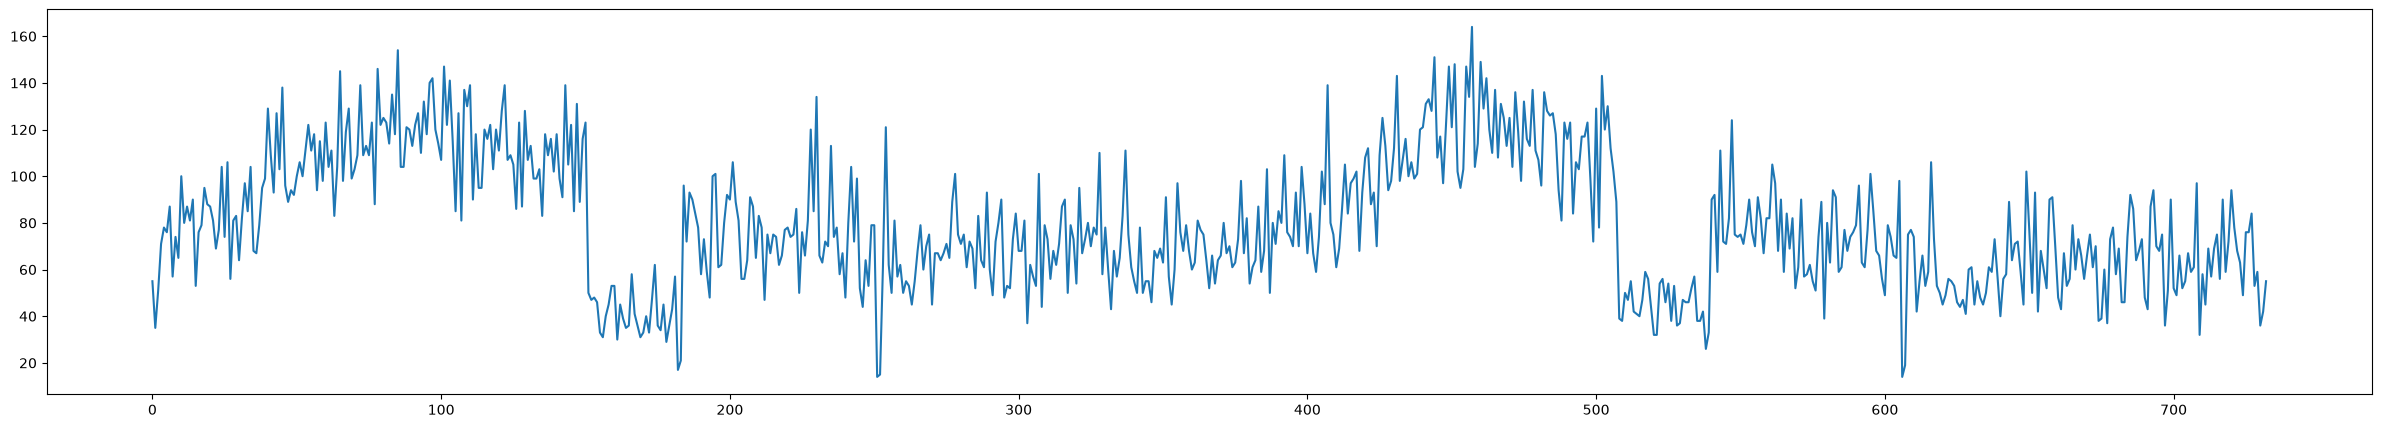

In [4]:
plt.figure(figsize=(30, 5))
plt.plot(df['chai_cups_sold'])

## Стационарный процесс  <a class="anchor" id="stacionary"></a>

Стационарный процесс - это случайный процесс, безусловное совместное распределение вероятностей которого не изменяется при сдвиге во времени. Следовательно, такие параметры, как среднее значение и дисперсия, также не меняются со временем, поэтому стационарные временные ряды легче прогнозировать.

Есть несколько способов установить, является ли временной ряд стационарным или нет, наиболее распространенными являются старая добрая визуализация, просмотр автокорреляции и выполнение статистических тестов.

Наиболее распространенным тестом является тест Дики-Фуллера (также называемый тест ADF), где нулевая гипотеза состоит в том, что временной ряд имеет единичный корень, другими словами, временной ряд не является стационарным.

Мы проверим, можно ли отвергнуть нулевую гипотезу, сравнив значение p с выбранным порогом (α), чтобы, если значение p меньше, мы могли отклонить нулевую гипотезу и предположить, что временной ряд с уверенностью является стационарным. уровень 1-α (технически мы просто не можем сказать, что это не так)

Временной ряд имеет единичный корень, или порядок интеграции один, если его первые разности образуют стационарный ряд. Это условие записывается как
$y_t\thicksim I(1)$ если ряд первых разностей $\triangle y_t=y_t-y_{t-1}$ является стационарным $\triangle y_t\thicksim I(0)$.

При помощи этого теста проверяют значение коэффициента $a$ в  авторегрессионном уравнении первого порядка AR(1)
$y_t=a\cdot y_{t-1}+\varepsilon_t,$
где $y_t$ — временной ряд, а $\varepsilon$— ошибка.

Если $a=1$, то процесс имеет единичный корень, в этом случае ряд $y_t$ не стационарен, является интегрированным временным рядом первого порядка $I(1)$. Если $|a|<1$, то ряд стационарный $I(0)$.


In [5]:
# импортируем функцию, описывающую тест Дики-Фуллера
from statsmodels.tsa.stattools import adfuller

In [6]:
# всю теорию, описанную выше, реализуем с помощью statsmodels для проверки
# временного ряда перевозок на стационарность

alpha = 0.05
name = "Продано чашек чая"

# определяем временной ряд отдельной переменной
ts = df['chai_cups_sold']

print(f'Тест Дики-Фуллера ряда {name} :')
# определяем результат значения теста из библиотеки с учетом
dftest = adfuller(ts, autolag='AIC')
dfoutput = pd.Series(dftest[0:4], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used'])

for key,value in dftest[4].items():
    dfoutput['Critical Value (%s)'%key] = value
print(dfoutput)

if dfoutput["p-value"] < alpha:
    print(f"Значение p меньше {alpha * 100}%. Ряд стационарный.")
else:
    print(f"Значение p больше {alpha*100}%. Ряд не стационарный.")

Тест Дики-Фуллера ряда Продано чашек чая :
Test Statistic                  -2.375394
p-value                          0.148802
#Lags Used                      20.000000
Number of Observations Used    712.000000
Critical Value (1%)             -3.439568
Critical Value (5%)             -2.865608
Critical Value (10%)            -2.568936
dtype: float64
Значение p больше 5.0%. Ряд не стационарный.


C:\Users\krapa\AppData\Local\Temp\ipykernel_28960\2544228350.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(ts, autolag='AIC')


А теперь попробуем осуществить дифференцирование. Перед этим опять попробуем декомпозицию ряда.

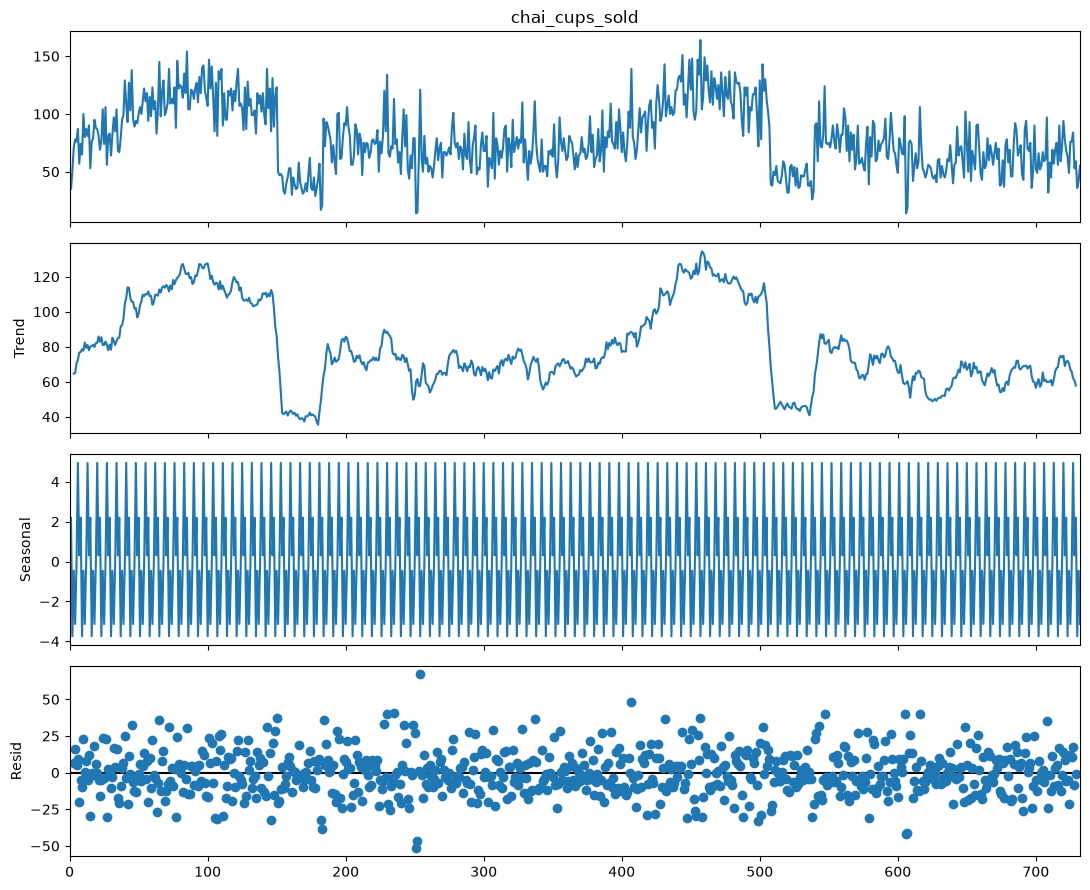

In [7]:
# импортируем функцию seasonal_decompose из statsmodels
# (то есть осуществляем декомпозицию сигнала/временного ряда)
from statsmodels.tsa.seasonal import seasonal_decompose

# задаем размер графика
from pylab import rcParams
rcParams['figure.figsize'] = 11, 9


# применяем функцию к данным о перевозках
decompose = seasonal_decompose(df['chai_cups_sold'], period=7)
decompose.plot()
plt.show()

Создадим два временных ряда на основе имеющегося, только без тренда и сезонности.

Удаляем тренд согласно формуле: $y' = y_t - y_{t-1}$;

Удаляем сезонность согласно формуле: $y' = y_t - y_{t-s}$;

In [8]:
nottrend = []
s = 7
notseason = []

# выборка без тренда
for i in range(1, len(df['chai_cups_sold'])):
   nottrend.append(df['chai_cups_sold'].iloc[i] - df['chai_cups_sold'].iloc[i-1])

# выборка без сезонности
for i in range(s, len(df['chai_cups_sold'])):
   notseason.append(df['chai_cups_sold'].iloc[i] - df['chai_cups_sold'].iloc[i-s])


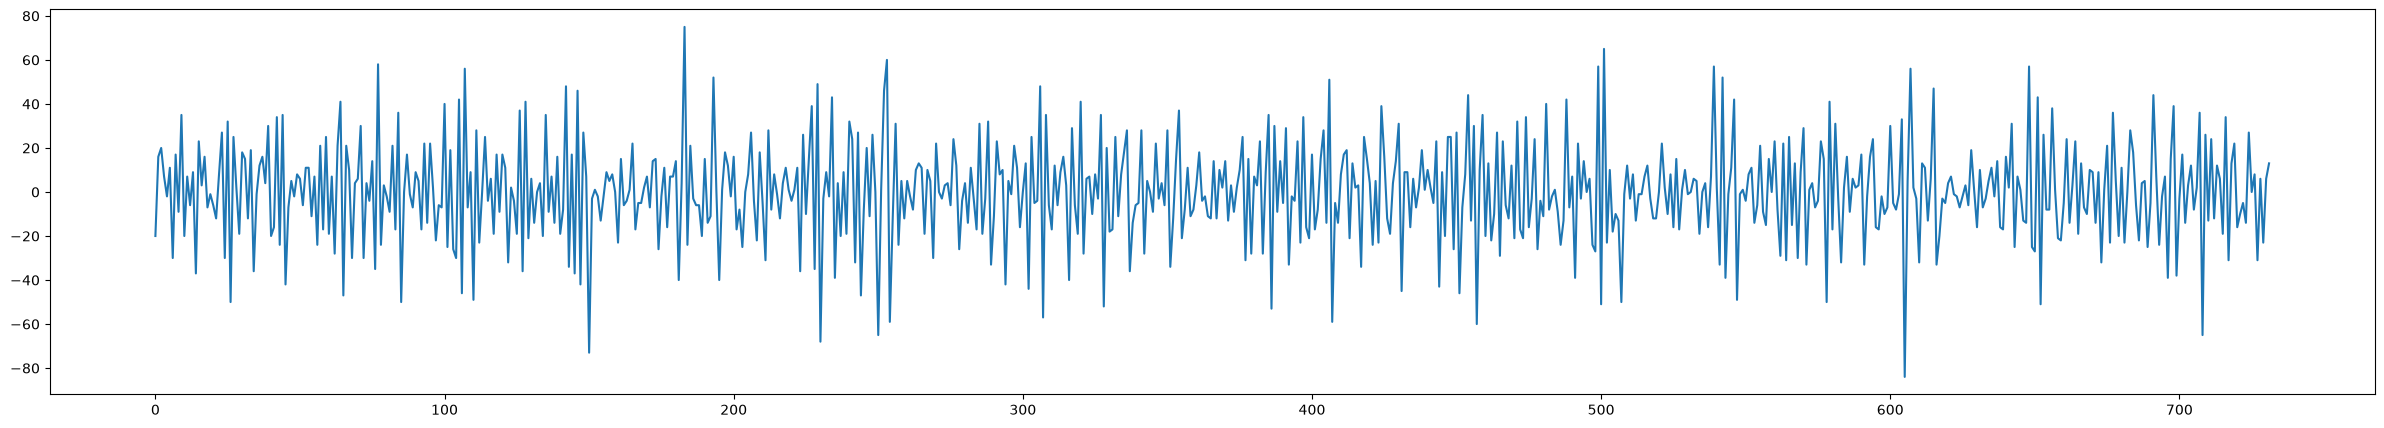

In [9]:
# отрисовываем временной ряд без тренда
plt.figure(figsize=(30, 5))
plt.plot(nottrend)

Теперь проведем тест Дики-Фуллера на временном ряде без тренда

In [10]:
alpha = 0.05
name = "Проданных чашек чая без тренда"
 
ts = nottrend

print(f'Тест Дики-Фуллера ряда {name} :')
dftest = adfuller(ts, autolag='AIC')
dfoutput = pd.Series(dftest[0:4], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used'])

for key,value in dftest[4].items():
    dfoutput['Critical Value (%s)'%key] = value
print(dfoutput)

if dfoutput["p-value"] < alpha:
    print(f"Значение p меньше {alpha * 100}%. Ряд стационарный.")
else:
    print(f"Значение p больше {alpha*100}%. Ряд не стационарный.")

Тест Дики-Фуллера ряда Проданных чашек чая без тренда :
Test Statistic                -7.299335e+00
p-value                        1.351525e-10
#Lags Used                     1.900000e+01
Number of Observations Used    7.120000e+02
Critical Value (1%)           -3.439568e+00
Critical Value (5%)           -2.865608e+00
Critical Value (10%)          -2.568936e+00
dtype: float64
Значение p меньше 5.0%. Ряд стационарный.


C:\Users\krapa\AppData\Local\Temp\ipykernel_28960\1553331829.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(ts, autolag='AIC')


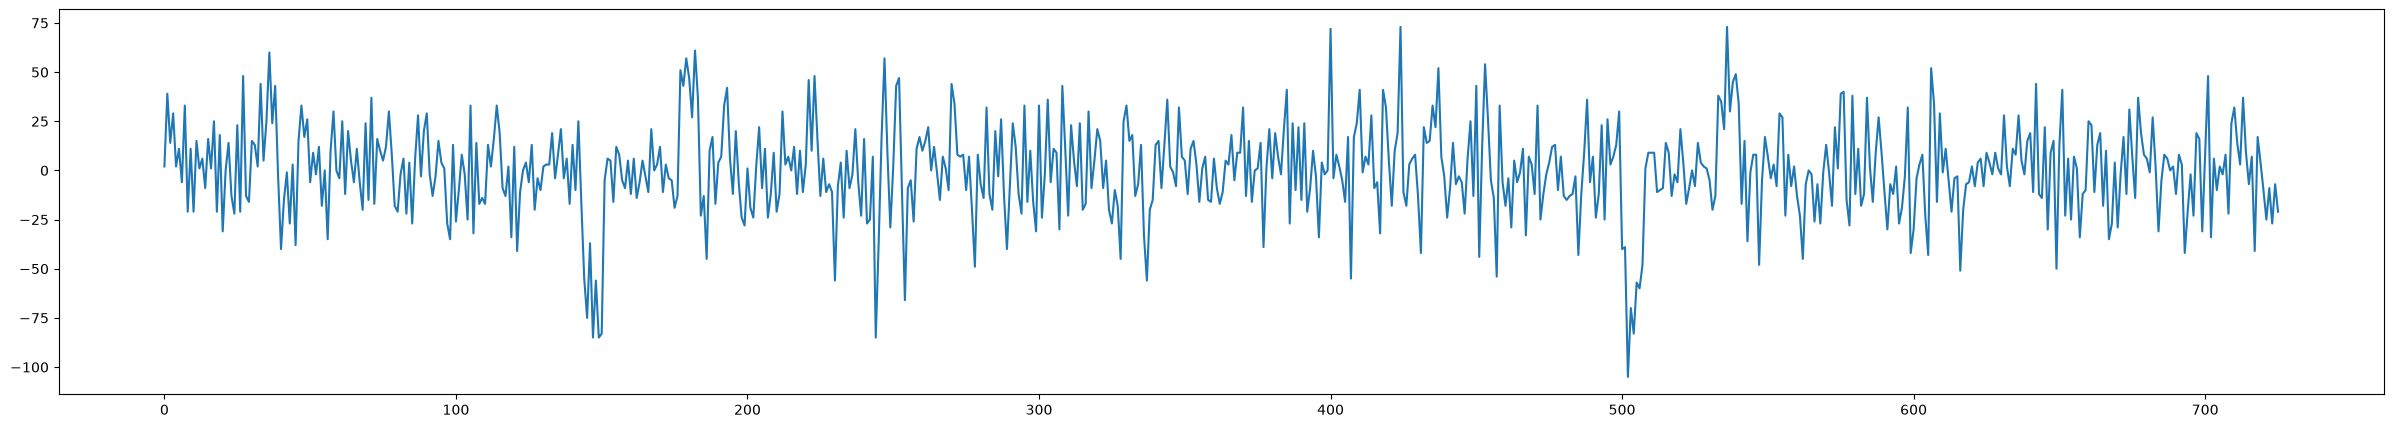

In [11]:
# отрисовываем временной ряд без сезонности
plt.figure(figsize=(30, 5))
plt.plot(notseason)

Аналогичным образом проведем тест Дики-Фуллера на временном ряде без сезонности

In [12]:
alpha = 0.05
name = "Проданных чашек чая  без сезона"
 
ts = notseason

print(f'Тест Дики-Фуллера ряда {name} :')
dftest = adfuller(ts, autolag='AIC')
dfoutput = pd.Series(dftest[0:4], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used'])

for key,value in dftest[4].items():
    dfoutput['Critical Value (%s)'%key] = value
print(dfoutput)

if dfoutput["p-value"] < alpha:
    print(f"Значение p меньше {alpha * 100}%. Ряд стационарный.")
else:
    print(f"Значение p больше {alpha*100}%. Ряд не стационарный.")

Тест Дики-Фуллера ряда Проданных чашек чая  без сезона :
Test Statistic                -6.066772e+00
p-value                        1.176663e-07
#Lags Used                     2.000000e+01
Number of Observations Used    7.050000e+02
Critical Value (1%)           -3.439660e+00
Critical Value (5%)           -2.865648e+00
Critical Value (10%)          -2.568958e+00
dtype: float64
Значение p меньше 5.0%. Ряд стационарный.


C:\Users\krapa\AppData\Local\Temp\ipykernel_28960\131411276.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(ts, autolag='AIC')


## Преобразование Бокса-Кокса <a class="anchor" id="boxcox"></a>

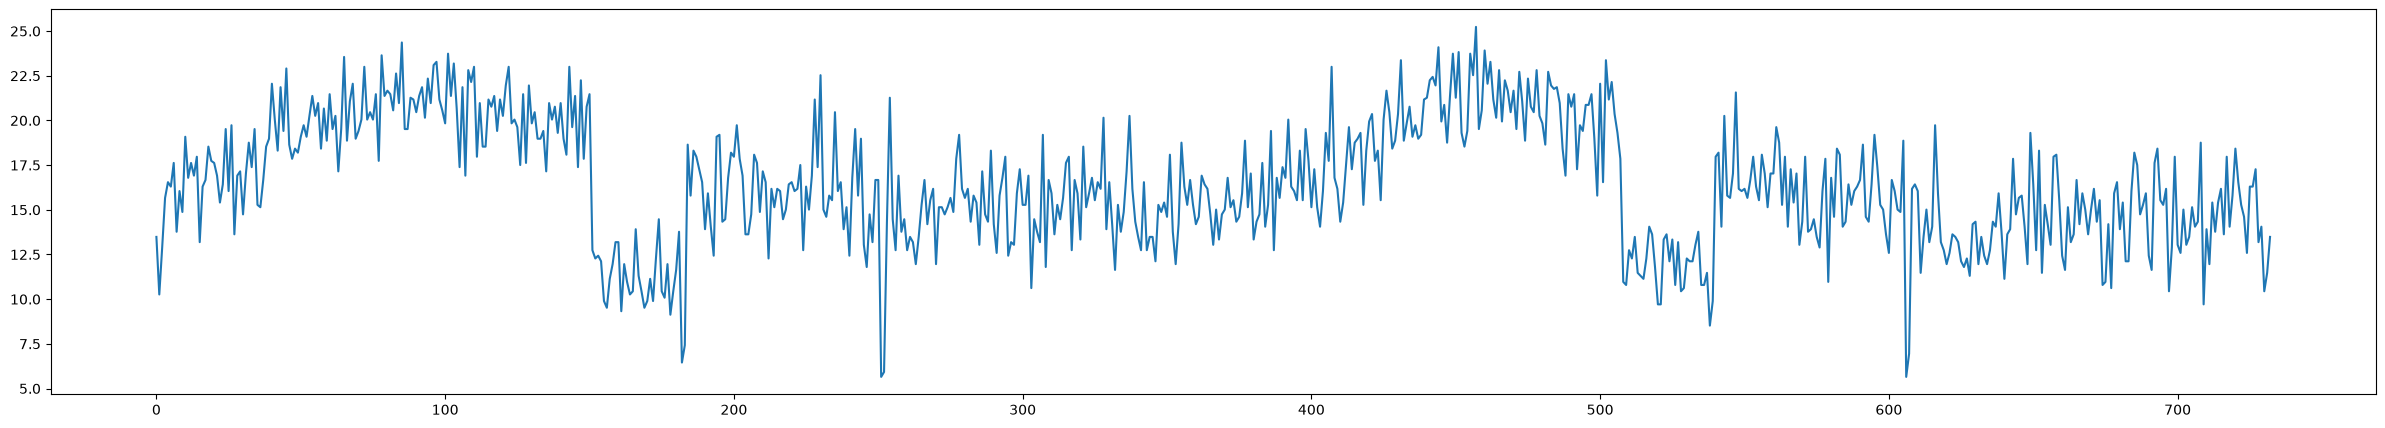

In [13]:
# Преобразование Бокса-Кокса
from scipy.stats import boxcox 

# вызываем функцию преобразования, которая выдает преобразованные данные и
# лучший параметр лямбда, который обеспечивает близость к нормальному
# распределению
transformed_data, best_lambda = boxcox(df['chai_cups_sold']) 

# а теперь посмотрим на преобразованные данные
plt.figure(figsize=(30, 5))
plt.plot(transformed_data) 

Попробуем теперь из преобразованного временного ряда удалить тренд и
визуализировать его

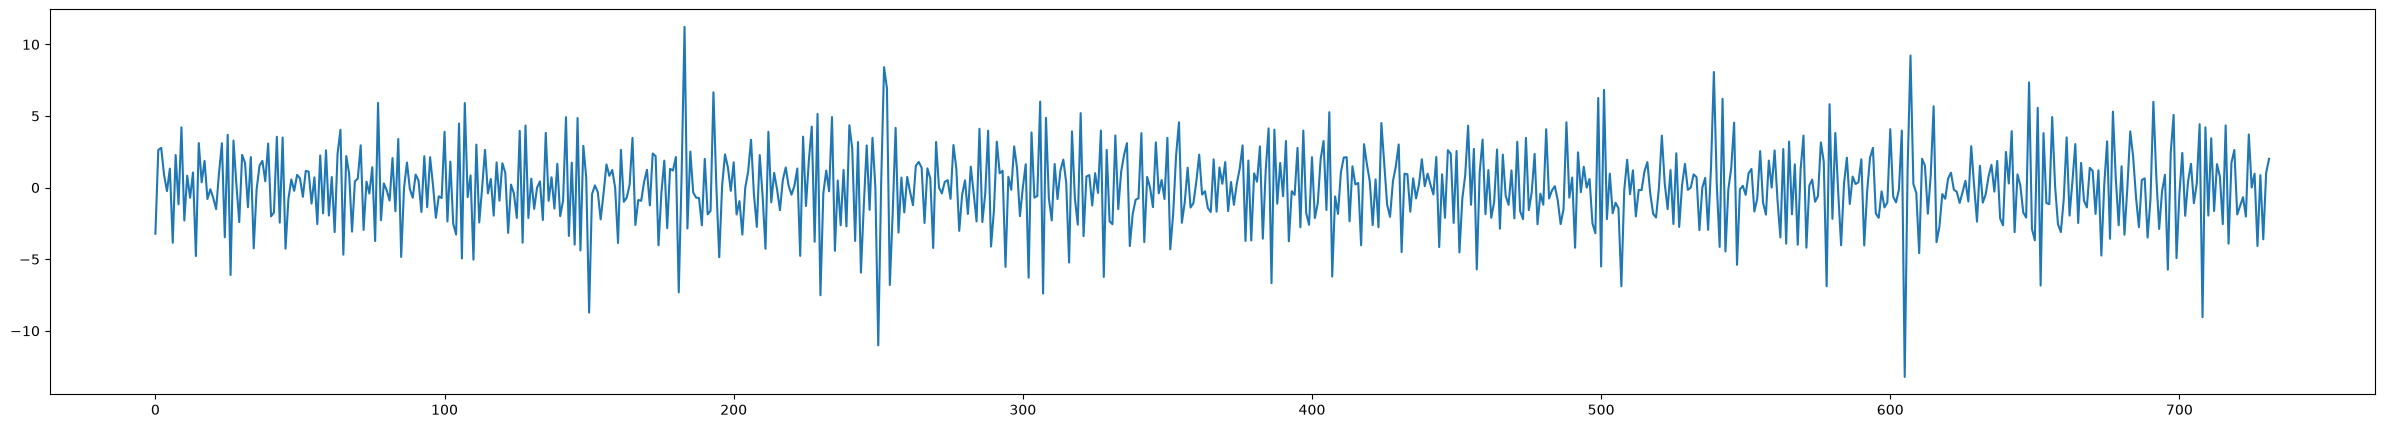

In [14]:
pnottrend = []

for i in range(1, len(transformed_data)):
   pnottrend.append(transformed_data[i] - transformed_data[i-1])

plt.figure(figsize=(30, 5))
plt.plot(pnottrend) 

Удалив тренд из преобразованного Боксом-Коксом ряда, попробуем опять проверить его на стационарность. Что-то изменилось?

In [15]:
alpha = 0.05
name = "Проданных чашек чая после Кокса-Бокса"
 
ts = pnottrend

print(f'Тест Дики-Фуллера ряда {name} :')
dftest = adfuller(ts, autolag='AIC')
dfoutput = pd.Series(dftest[0:4], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used'])

for key,value in dftest[4].items():
    dfoutput['Critical Value (%s)'%key] = value
print(dfoutput)

if dfoutput["p-value"] < alpha:
    print(f"Значение p меньше {alpha * 100}%. Ряд стационарный.")
else:
    print(f"Значение p больше {alpha*100}%. Ряд не стационарный.")

Тест Дики-Фуллера ряда Проданных чашек чая после Кокса-Бокса :
Test Statistic                -7.317167e+00
p-value                        1.220709e-10
#Lags Used                     1.900000e+01
Number of Observations Used    7.120000e+02
Critical Value (1%)           -3.439568e+00
Critical Value (5%)           -2.865608e+00
Critical Value (10%)          -2.568936e+00
dtype: float64
Значение p меньше 5.0%. Ряд стационарный.


C:\Users\krapa\AppData\Local\Temp\ipykernel_28960\933366384.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(ts, autolag='AIC')


## Модели для предсказания значений временного ряда <a class="anchor" id="predict"></a>

Первой моделью будет модель **AR**, или же autoregression - модель, которая использует связь между наблюдением и некоторым количеством предыдущих наблюдений.​

Сделаем случайный ряд и затем поработаем с ним.

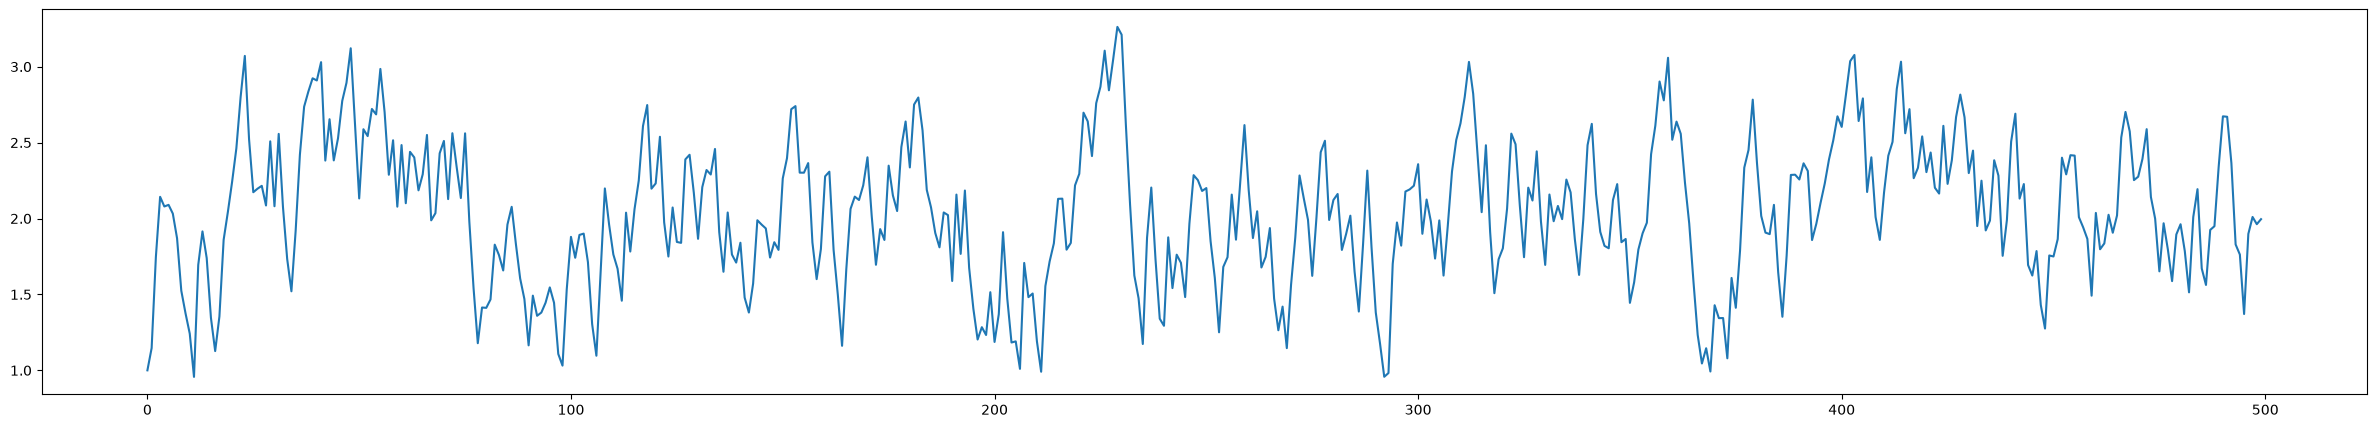

In [16]:
# AR(1)

N = 500

ar1 = [1]

for i in range(1, N):
    ar1.append(0.76 * ar1[i-1] + np.random.random())
plt.figure(figsize=(30, 5))
plt.plot(ar1)

Посмотрим какие у него стандартное отклонение и среднее.

In [17]:
print(f"standart deviation = {np.std(ar1)}\n mean = {np.mean(ar1)}")

standart deviation = 0.4685728366550054
 mean = 2.0342017372553034


А теперь обернем его в датафрейм и посмотрим его обычную и частичную автокорреляцию. Что можно сказать по поводу этого временного ряда, глядя на эти параметры?

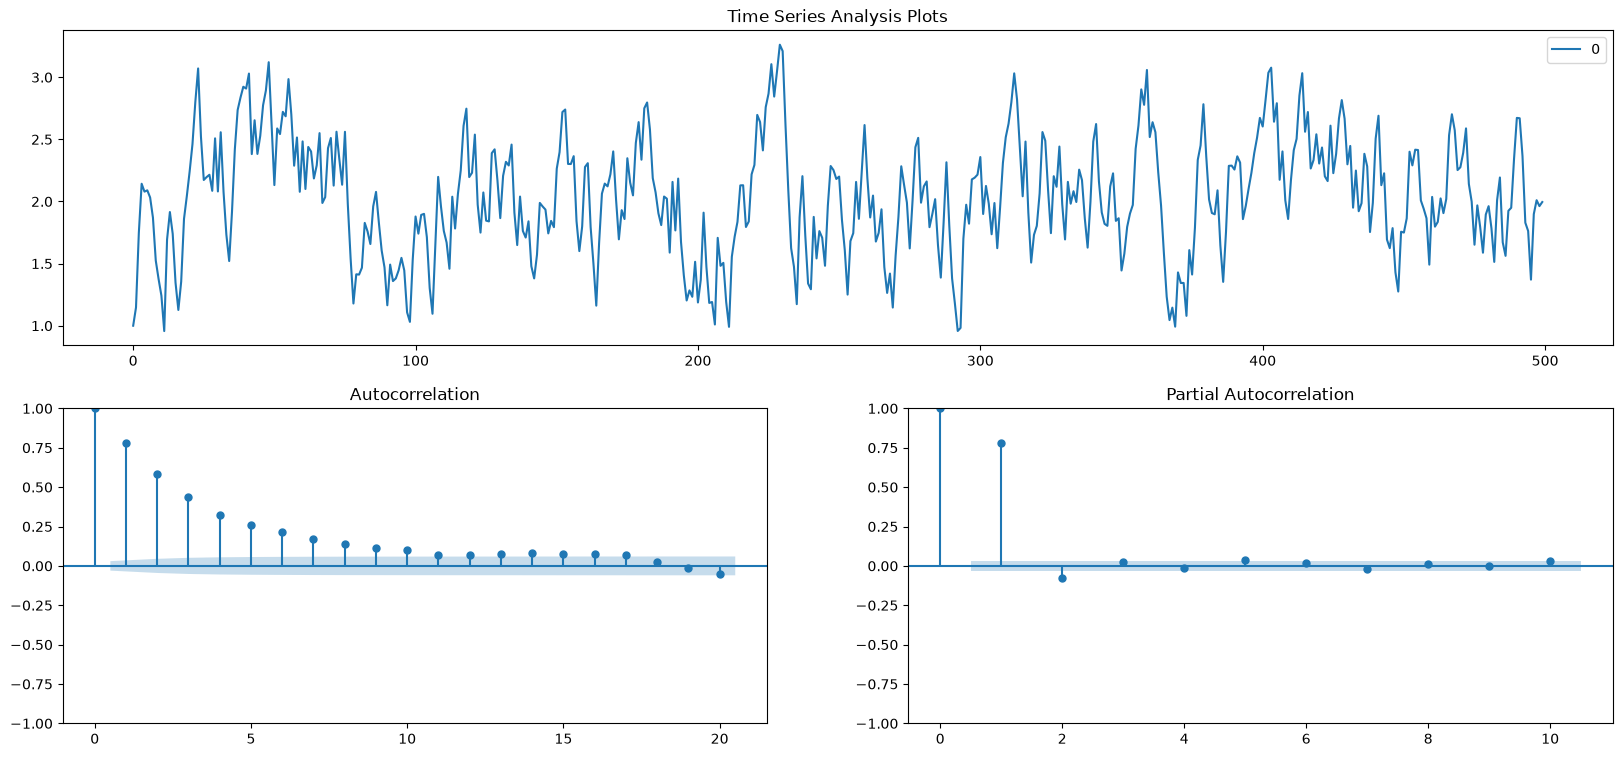

In [18]:
ts = pd.DataFrame(ar1)

fig = plt.figure(figsize=(20, 9))
layout = (2, 2)
ts_ax = plt.subplot2grid(layout, (0, 0), colspan=2)
acf_ax = plt.subplot2grid(layout, (1, 0))
pacf_ax = plt.subplot2grid(layout, (1, 1))

ts.plot(ax=ts_ax)
ts_ax.set_title('Time Series Analysis Plots')
smt.graphics.plot_acf(ts, lags=20, ax=acf_ax, alpha=0.5)
smt.graphics.plot_pacf(ts, lags=10, ax=pacf_ax, alpha=0.5)
None

Сделаем ещё один случайный ряд, но уже и с отрицательными значениями коэффициента

standart deviation = 0.4115782121562633
 mean = 0.2791674866906832


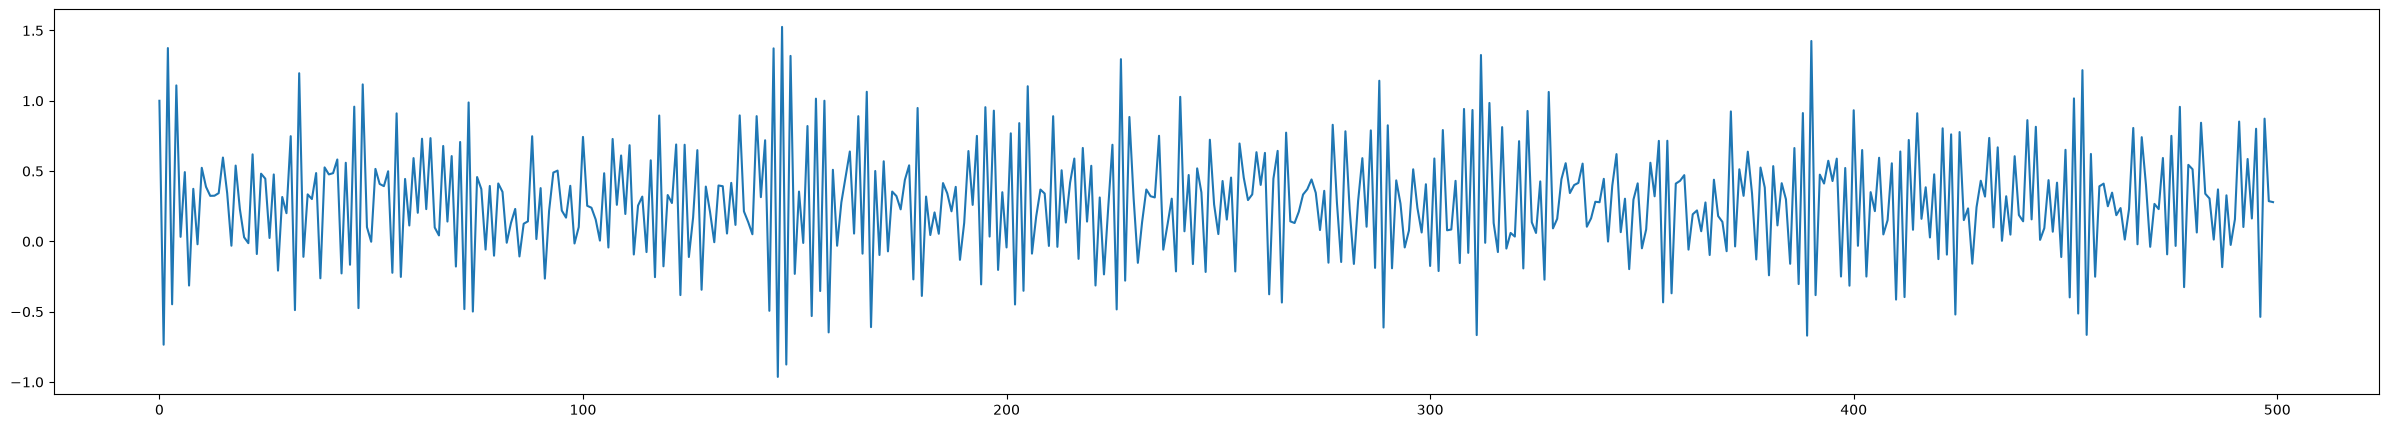

In [19]:
# AR(1)

N = 500

ar2 = [1]

for i in range(1, N):
    ar2.append(- 0.76*ar2[i-1] + np.random.random())
plt.figure(figsize=(30, 5))
plt.plot(ar2)

print(f"standart deviation = {np.std(ar2)}\n mean = {np.mean(ar2)}")

А что можно сказать по поводу этого ряда?

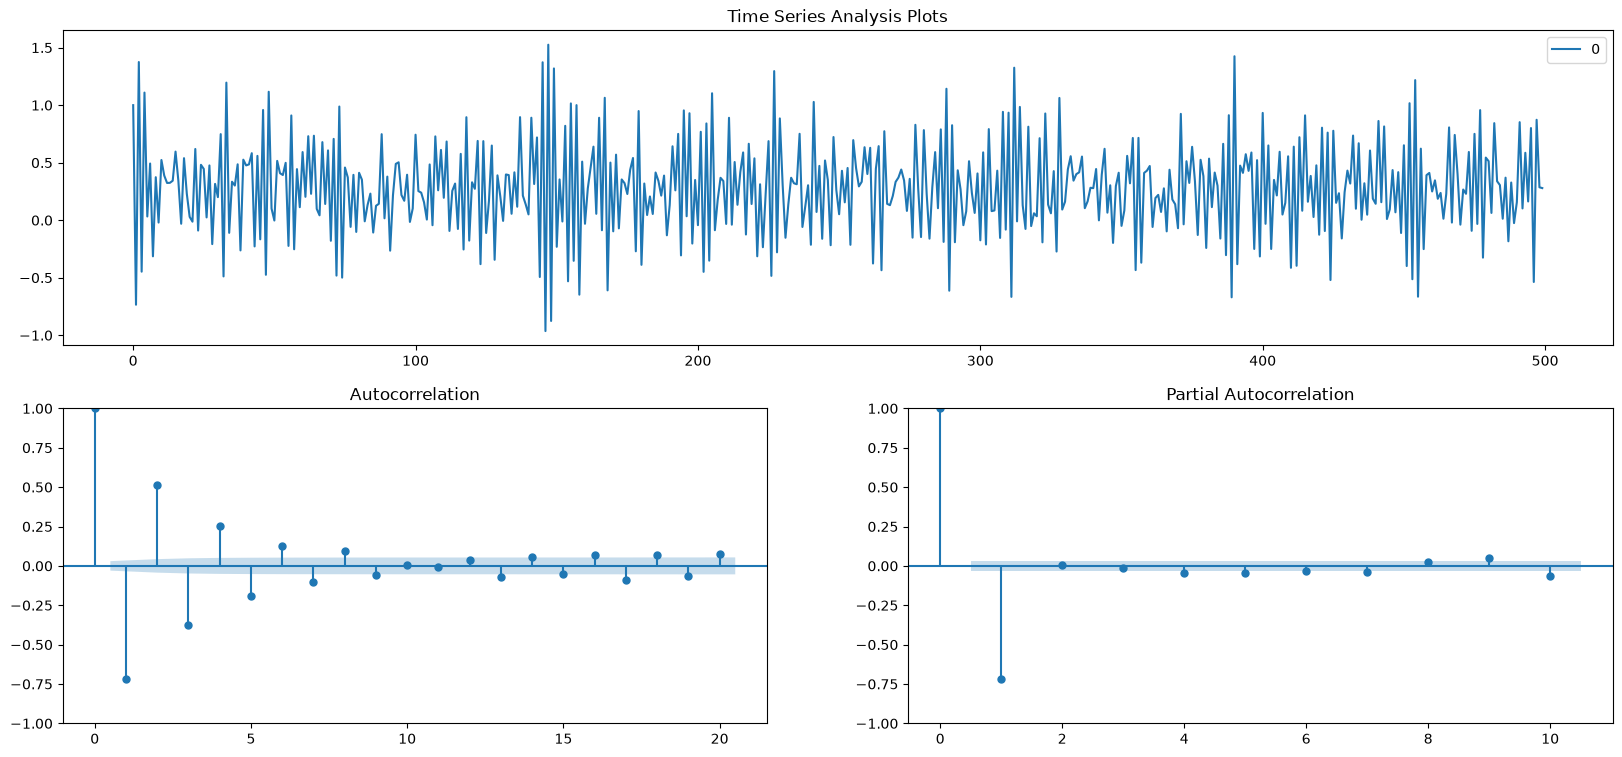

In [20]:
ts = pd.DataFrame(ar2)

fig = plt.figure(figsize=(20, 9))
layout = (2, 2)
ts_ax = plt.subplot2grid(layout, (0, 0), colspan=2)
acf_ax = plt.subplot2grid(layout, (1, 0))
pacf_ax = plt.subplot2grid(layout, (1, 1))

ts.plot(ax=ts_ax)
ts_ax.set_title('Time Series Analysis Plots')
smt.graphics.plot_acf(ts, lags=20, ax=acf_ax, alpha=0.5)
smt.graphics.plot_pacf(ts, lags=10, ax=pacf_ax, alpha=0.5)
None

А теперь коэффициент >1 

standart deviation = 0.4115782121562633
 mean = 0.2791674866906832


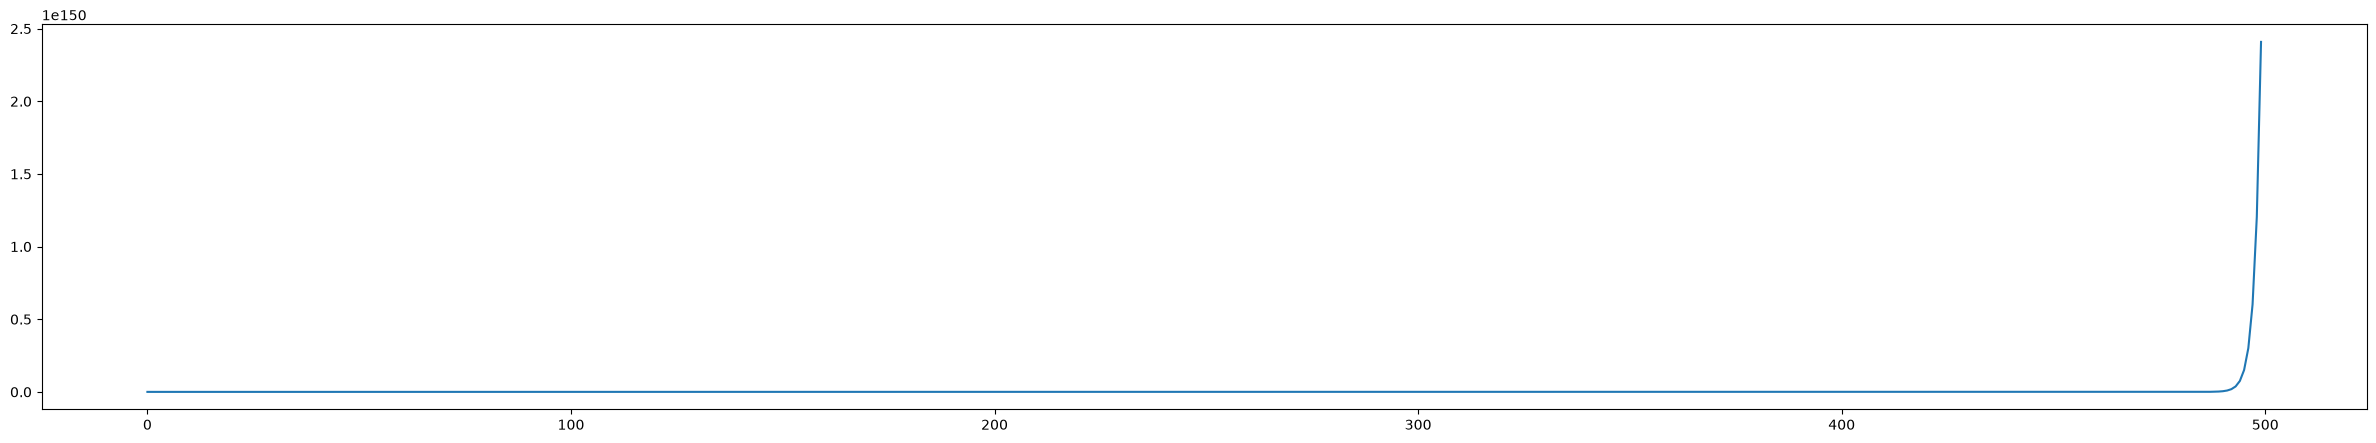

In [21]:
# AR(1)

N = 500

ar3 = [1]

for i in range(1, N):
    ar3.append(2 * ar3[i-1] + np.random.random())
plt.figure(figsize=(30, 5))
plt.plot(ar3)

print(f"standart deviation = {np.std(ar2)}\n mean = {np.mean(ar2)}")

Ладно, пора возвращаться к прогнозированию. Следаем прогноз с помощью AR модели, предварительно поделив выборки на обучающую, валидационную и тестовую.

In [22]:

df['t'] = df.index.values

ln = len(df)

# указываем 'объемы' выборок
train_cutoff = int(round(ln*0.75, 0))
validate_cutoff = int(round(ln*0.90,0))

# делим выборки
train_df = df[df['t'] <= train_cutoff]
validate_df = df[(df['t'] > train_cutoff) & (df['t'] <= validate_cutoff)]
forecast_df = df[df['t'] > validate_cutoff]

Визуализируем поделенные выборки.

* Обучающая выборка - синим цветом
* Валидационная выборка - оранжевым цветом
* Предсказываемая выборка - зеленым цветом

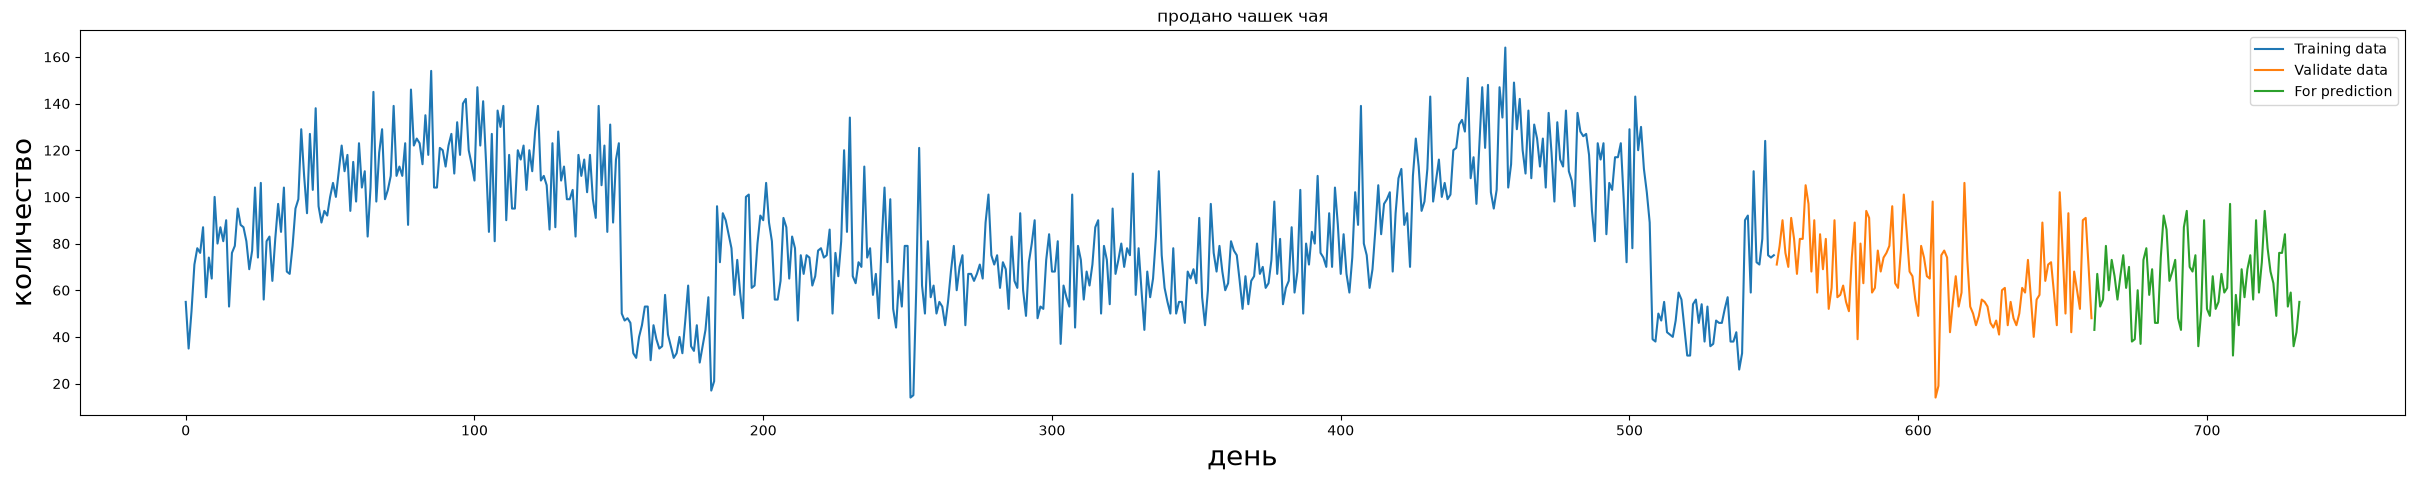

In [23]:
plt.figure(figsize=(30, 5))
plt.plot(train_df.t, train_df.chai_cups_sold, label='Training data')
plt.plot(validate_df.t, validate_df.chai_cups_sold, label='Validate data')
plt.plot(forecast_df.t, forecast_df.chai_cups_sold, label='For prediction')
plt.legend()

plt.title('продано чашек чая')
plt.ylabel('количество', fontsize="20")
plt.xlabel('день', fontsize="20")
plt.show()

In [24]:
from statsmodels.tsa.ar_model import AutoReg, ar_select_order

In [25]:
# создаем объект модели на основе данных временного ряда с 7 лагами

mod = AutoReg(train_df.chai_cups_sold, 7)
# обучаем
res = mod.fit()

# выводим сводку информации об авторегрессионной модели
print(res.summary())

                            AutoReg Model Results                             
Dep. Variable:         chai_cups_sold   No. Observations:                  544
Model:                     AutoReg(7)   Log Likelihood               -2349.940
Method:               Conditional MLE   S.D. of innovations             18.189
Date:                Sat, 21 Nov 2026   AIC                           4717.879
Time:                        10:42:23   BIC                           4756.570
Sample:                             7   HQIC                          4733.006
                                  551                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 6.4972      2.752      2.361      0.018       1.104      11.890
chai_cups_sold.L1     0.2639      0.042      6.240      0.000       0.181       0.347
chai_cups_sold.L2     0.

In [26]:
# опять обучаем модель, но на этот раз указываем тип ковариационной оценки
res = mod.fit(cov_type="HC0")

# смотрим, что изменилось
print(res.summary())

                            AutoReg Model Results                             
Dep. Variable:         chai_cups_sold   No. Observations:                  544
Model:                     AutoReg(7)   Log Likelihood               -2349.940
Method:               Conditional MLE   S.D. of innovations             18.189
Date:                Sat, 21 Nov 2026   AIC                           4717.879
Time:                        10:42:23   BIC                           4756.570
Sample:                             7   HQIC                          4733.006
                                  551                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 6.4972      2.717      2.391      0.017       1.172      11.823
chai_cups_sold.L1     0.2639      0.051      5.175      0.000       0.164       0.364
chai_cups_sold.L2     0.

Продолжаем экспериментировать

In [68]:
sel = ar_select_order(train_df.chai_cups_sold, 7, seasonal=True, period=365, trend='ct')
sel.ar_lags
res = sel.model.fit()
print(res.summary())

                            AutoReg Model Results                             
Dep. Variable:         chai_cups_sold   No. Observations:                  549
Model:               Seas. AutoReg(2)   Log Likelihood               -2103.803
Method:               Conditional MLE   S.D. of innovations             11.169
Date:                Sat, 21 Nov 2026   AIC                           4945.605
Time:                        11:17:00   BIC                           6535.293
Sample:                             2   HQIC                          5566.879
                                  551                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                33.6933     11.927      2.825      0.005      10.316      57.070
trend                -0.0042      0.003     -1.321      0.186      -0.011       0.002
s(2,365)             -9.

Смотрим, что он предсказал

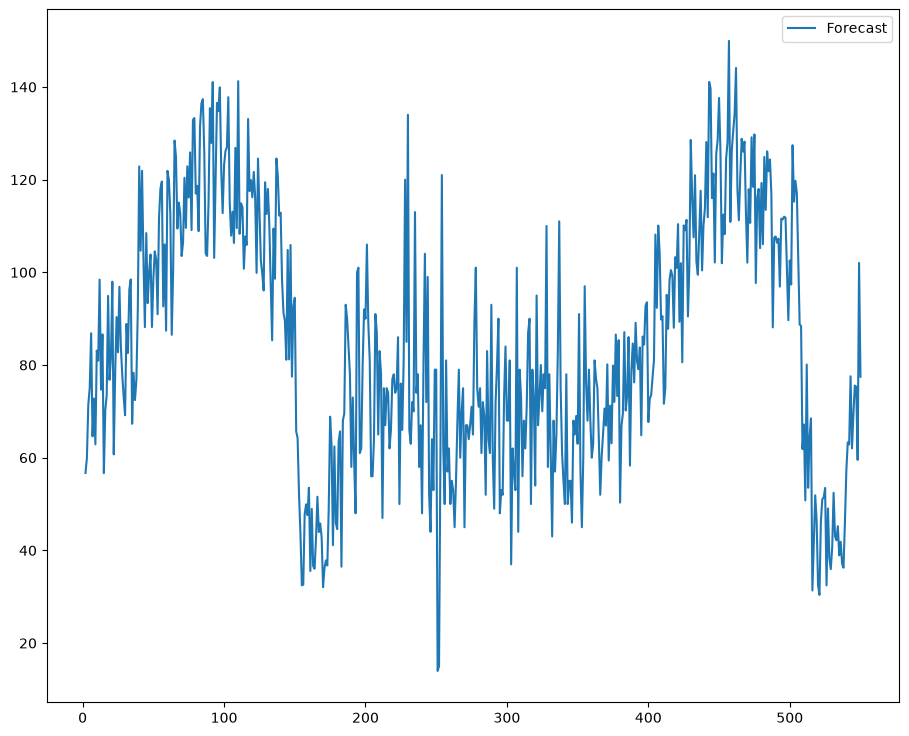

In [69]:
fig = res.plot_predict(
    start=0,
    end=train_cutoff,
    dynamic=False
)
plt.show()

Формируем предсказанные временные ряды

In [72]:
pred = res.predict(start=0, end=train_cutoff, dynamic=False)
v_pred = res.predict(start=train_cutoff+1, end=(validate_cutoff), dynamic=False)
f_pred = res.predict(start=validate_cutoff + 1, end=(forecast_df.t[len(df.t)-1]), dynamic=False)

Отрисовываем их

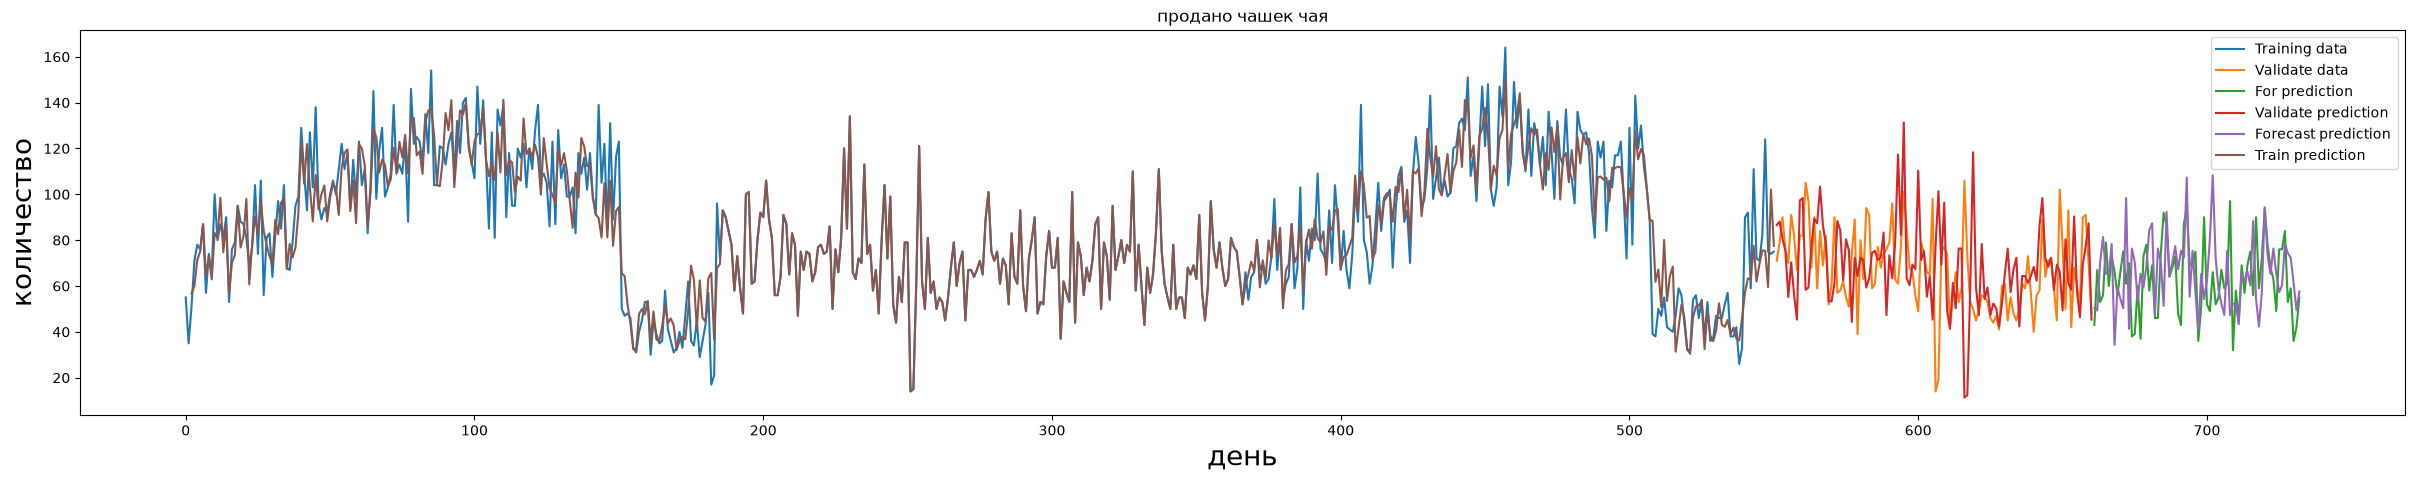

In [73]:
plt.figure(figsize=(30, 5))
plt.plot(train_df.t, train_df.chai_cups_sold, label='Training data')
plt.plot(validate_df.t, validate_df.chai_cups_sold, label='Validate data')
plt.plot(forecast_df.t, forecast_df.chai_cups_sold, label='For prediction')
plt.plot(validate_df.t, v_pred, label='Validate prediction ')
plt.plot(forecast_df.t, f_pred, label='Forecast prediction')
plt.plot(train_df.t, pred, label='Train prediction')

plt.legend()
plt.title('продано чашек чая')
plt.ylabel('количество', fontsize="20")
plt.xlabel('день', fontsize="20")
plt.show()

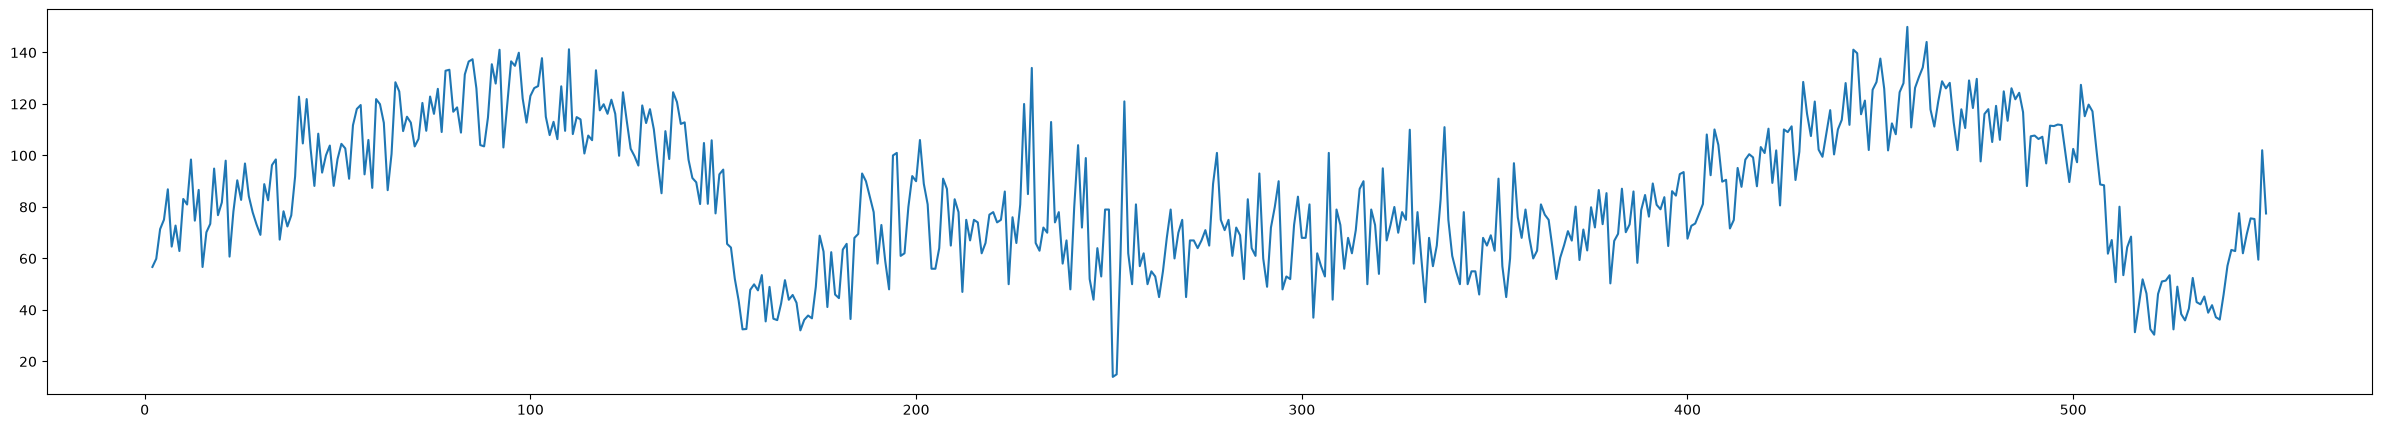

In [74]:
plt.figure(figsize=(30, 5))
plt.plot(pred)

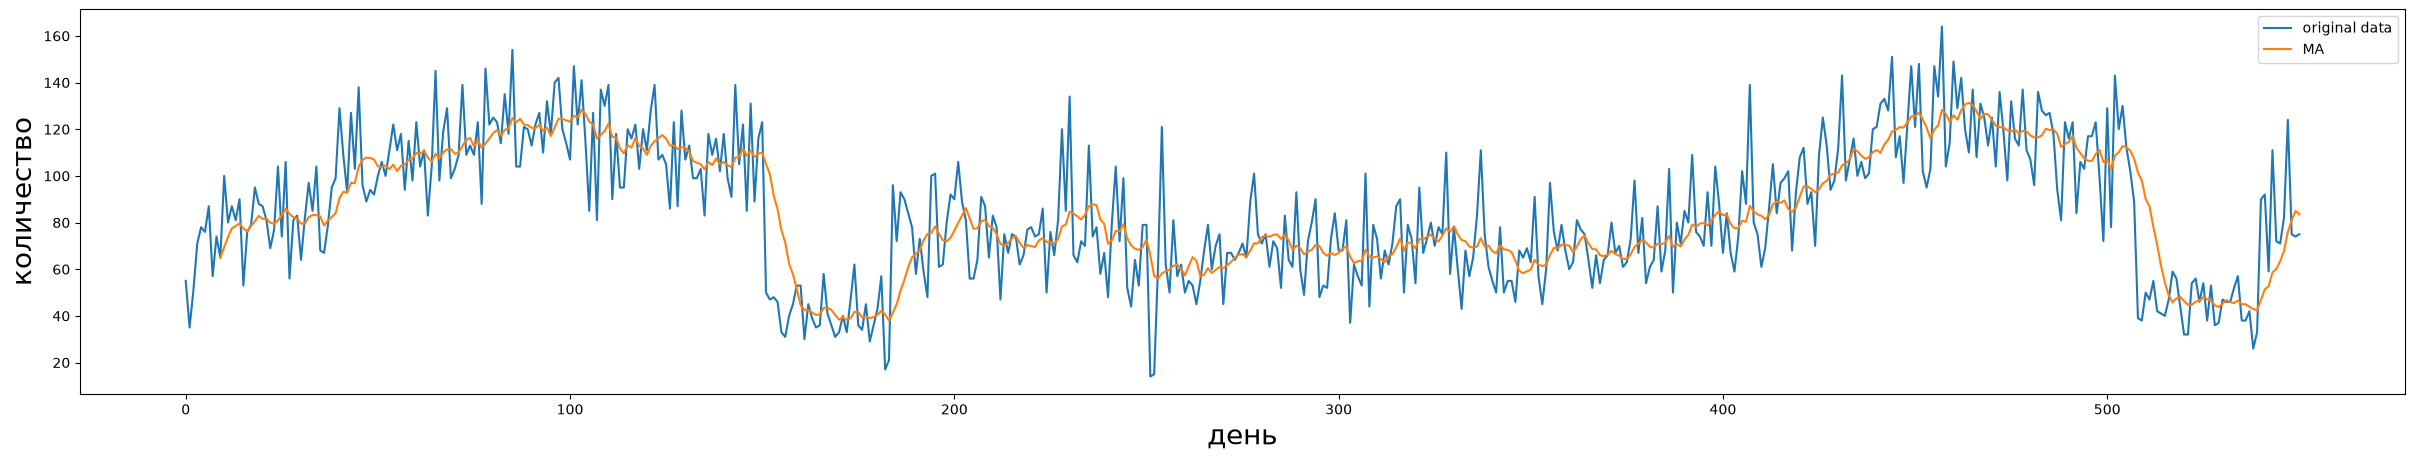

In [75]:

df['t'] = df.index.values

ln = len(df)

# указываем 'объемы' выборок
train_cutoff = int(round(ln*0.75, 0))
validate_cutoff = int(round(ln*0.90,0))

# делим выборки
train_df = df[df['t'] <= train_cutoff]
validate_df = df[(df['t'] > train_cutoff) & (df['t'] <= validate_cutoff)]
forecast_df = df[df['t'] > validate_cutoff]

plt.figure(figsize=(30, 5))
plt.plot(train_df["t"], train_df["chai_cups_sold"], label="original data")
plt.plot(train_df["t"], train_df["chai_cups_sold"].rolling(10).mean(), label="MA")
plt.legend()
plt.ylabel('количество', fontsize="20")
plt.xlabel('день', fontsize="20")
plt.show()

## Метрики точности прогноза <a class="anchor" id="metrics"></a>

* R2- коэффициент детерминации     ​
* MSE (RMSE) – mean squared error – среднеквадратичная ошибка​
* MAE – mean absolute error – средняя абсолютная ошибка​
* MAPE – mean absolute percentage error – средняя абсолютная ошибка в %​
* SMAPE – symmetric mean absolute percentage error – симметричная средняя абсолютная ошибка в %

Определяем метрики точности прогноза из библиотеки sklearn. Попробуй определить последнюю оставшуюся метрику **SMAPE** самостоятельно.

In [76]:
from sklearn.metrics import mean_absolute_percentage_error, mean_absolute_error, mean_squared_error, r2_score

Вычислим значения ошибок модели AR, опираясь на предсказанные ею значения forecast.

In [77]:
print("RMSE:", np.sqrt(mean_squared_error(forecast_df.chai_cups_sold, f_pred)))
print("MAPE:", mean_absolute_percentage_error(forecast_df.chai_cups_sold, f_pred))
print("MAE:", mean_absolute_error(forecast_df.chai_cups_sold, f_pred))
print("R2: ", r2_score(forecast_df.chai_cups_sold, f_pred))

RMSE: 20.057569113778694
MAPE: 0.27685254458820374
MAE: 16.162681332024793
R2:  -0.6733392912390752


In [78]:
smape = np.mean(np.abs(f_pred - forecast_df.chai_cups_sold) /((np.abs(f_pred) + np.abs(forecast_df.chai_cups_sold)) / 2))
print("SMAPE:", smape * 100, "%")

SMAPE: 25.541852224056328 %
